# EDA and Processing

This notebook covers exploratory data analysis and preprocessing for the smart maintenance dataset, ahead of two modeling tasks:
- Regression - predicting `Failure_Prob`
- Classification - predicting `Maintenance_Priority` (3 classes)

## Import and Setup

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

current_dir = Path.cwd()
project_root = current_dir if (current_dir / "src").exists() else current_dir.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.utils import load_raw_data
from src.utils import DATA_PROCESSED_PATH

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
sns.set_palette("colorblind")

print("Import and Setup successfully.")

Import and Setup successfully.


In [2]:
df = load_raw_data()
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 1430 entries, 0 to 1429
Data columns (total 10 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Machine_ID                   1430 non-null   str    
 1   Temp_C                       1430 non-null   float64
 2   Vibration_mm_s               1430 non-null   float64
 3   Pressure_Bar                 1430 non-null   float64
 4   Acoustic_dB                  1430 non-null   float64
 5   Inspection_Duration_min      1430 non-null   int64  
 6   Downtime_Cost_USD            1430 non-null   int64  
 7   Technician_Availability_pct  1430 non-null   int64  
 8   Failure_Prob                 1430 non-null   float64
 9   Maintenance_Priority         1430 non-null   int64  
dtypes: float64(5), int64(4), str(1)
memory usage: 111.8 KB
None


## Data Integrity Check

In [3]:
print(f"Missing Values: {df.isna().sum().sum()}")
print(f"Duplicate Rows: {df.duplicated().sum()}")

Missing Values: 0
Duplicate Rows: 0


In [4]:
numeric_cols = df.select_dtypes(include=[np.number]).columns
display(df[numeric_cols].describe().T[['min', 'mean', '50%', 'max', 'std']])

,min,mean,50%,max,std
Temp_C,41.483895,75.457760,75.473914,109.958778,9.957299
Vibration_mm_s,-0.886814,2.492967,2.493069,5.420753,0.993764
Pressure_Bar,3.477036,5.006490,5.000584,7.026275,0.493718
Acoustic_dB,35.330958,70.167973,70.219443,97.989795,10.134302
Inspection_Duration_min,30.000000,89.217483,89.000000,149.000000,34.830122
Downtime_Cost_USD,502.000000,2718.568531,2681.500000,4998.000000,1296.430507
Technician_Availability_pct,50.000000,74.430070,74.000000,99.000000,14.450429
Failure_Prob,0.310000,0.491965,0.490000,0.660000,0.056898
Maintenance_Priority,1.000000,1.836364,2.000000,3.000000,0.490433


In [5]:
negative_vib = (df['Vibration_mm_s'] < 0).sum()
if negative_vib > 0:
    print(f"Found {negative_vib} negative values in Vibration_mm_s. Clipping to 0...")
    df['Vibration_mm_s'] = df['Vibration_mm_s'].clip(lower=0)

Found 11 negative values in Vibration_mm_s. Clipping to 0...


## Target Variables and Features Analysis

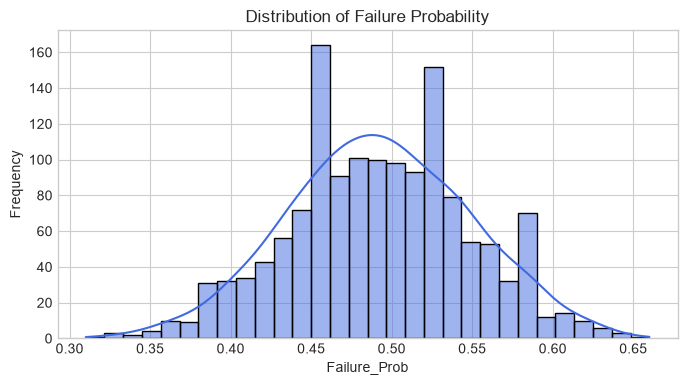

In [6]:
plt.figure(figsize=(8, 4))
sns.histplot(df['Failure_Prob'], kde=True, bins=30, color='royalblue')
plt.title('Distribution of Failure Probability')
plt.xlabel('Failure_Prob')
plt.ylabel('Frequency')
plt.show()

Maintenance_Priority Distribution (%):
 Maintenance_Priority
1    21.538462
2    73.286713
3     5.174825
Name: proportion, dtype: float64


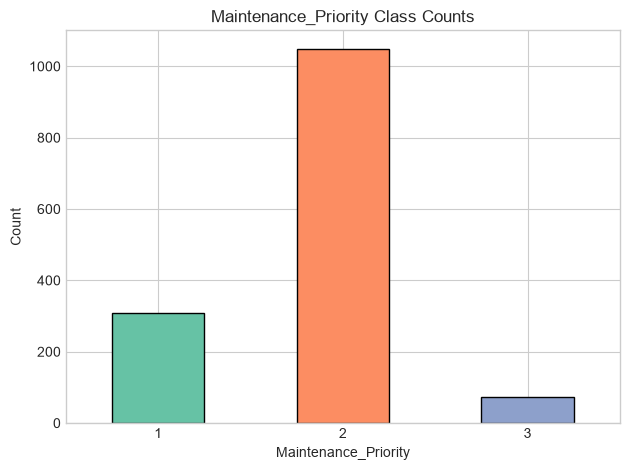

In [7]:
priority_counts = df["Maintenance_Priority"].value_counts(normalize=True).sort_index() * 100
print("Maintenance_Priority Distribution (%):\n", priority_counts)

df["Maintenance_Priority"].value_counts().sort_index().plot(kind='bar',color=['#66c2a5', '#fc8d62', '#8da0cb'], edgecolor='black')
plt.title("Maintenance_Priority Class Counts")
plt.xlabel("Maintenance_Priority")
plt.ylabel("Count")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

**Class imbalance.** `Maintenance_Priority` is imbalanced (Class 2 = 73.3%, Class 1 = 21.5%, Class 3 = 5.2%). The classification task should use stratified splits and may benefit from class weighting or resampling.

In [8]:
# Domain Feature
# Feature 1: Compound physical stress
df["Severity_Index"] = df["Temp_C"] * df["Vibration_mm_s"]

# Feature 2: Operational resource risk
df["Resource_Risk"] = df["Downtime_Cost_USD"] / (df["Technician_Availability_pct"] + 1e-5)   # add epsilon to avoid divided by zero

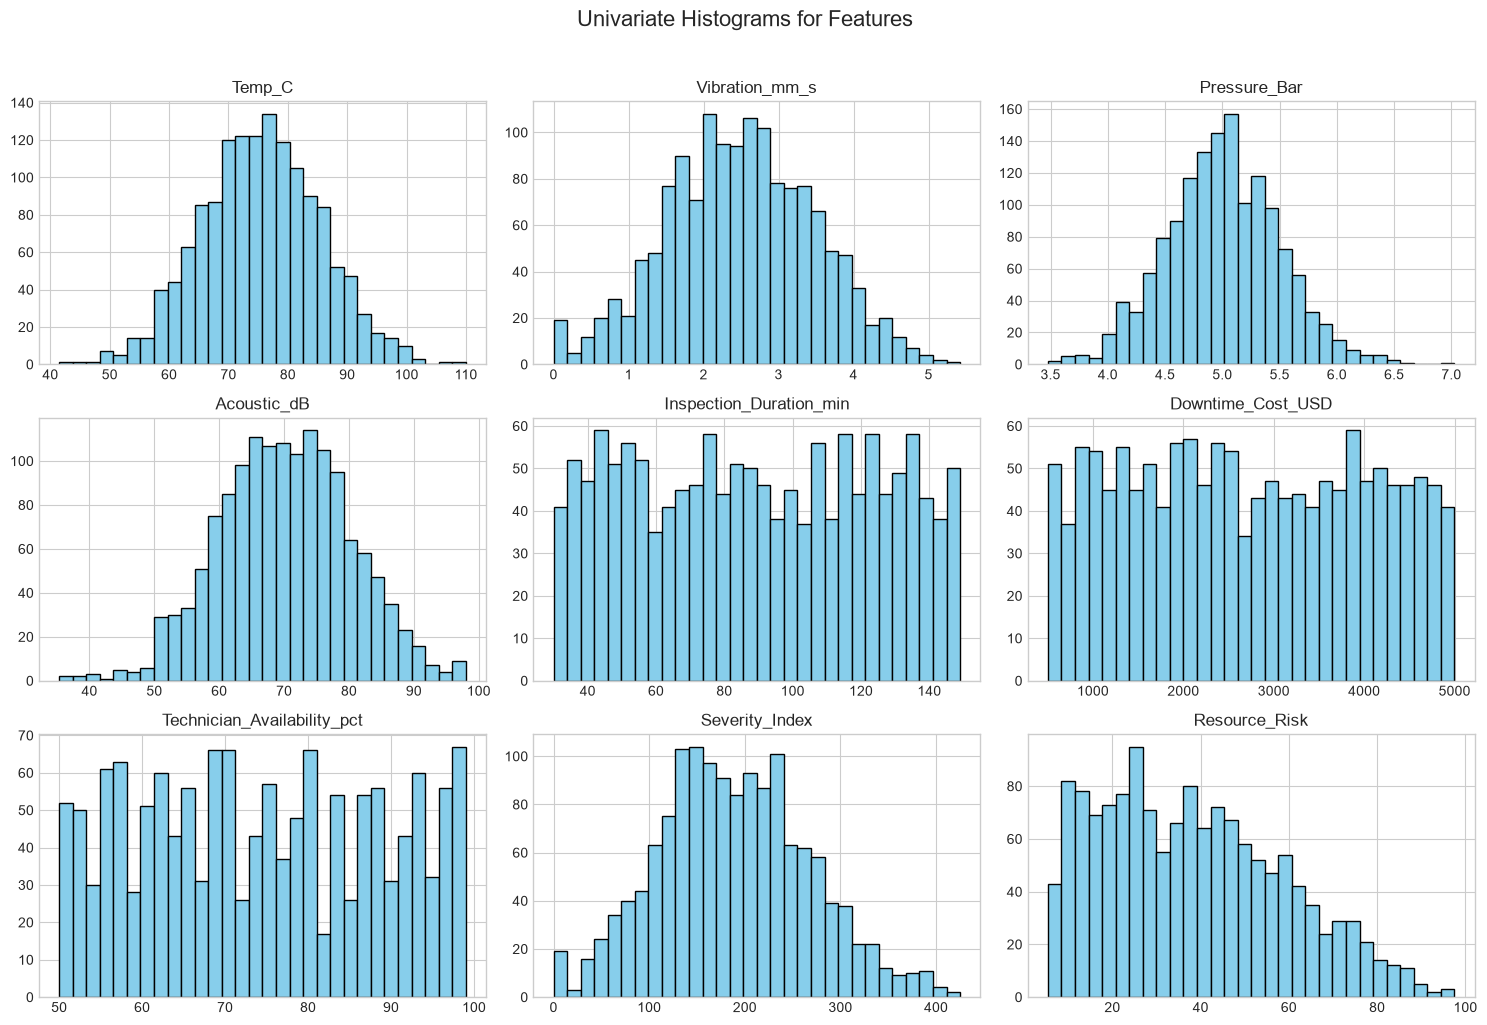

In [9]:
exclude_cols = ["Machine_ID", "Failure_Prob", "Maintenance_Priority"]
num_cols = df.select_dtypes(include=[np.number]).columns.drop(
    exclude_cols, errors="ignore"
)

df[num_cols].hist(bins=30, figsize=(15, 10), color="skyblue", edgecolor="black")
plt.suptitle("Univariate Histograms for Features", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

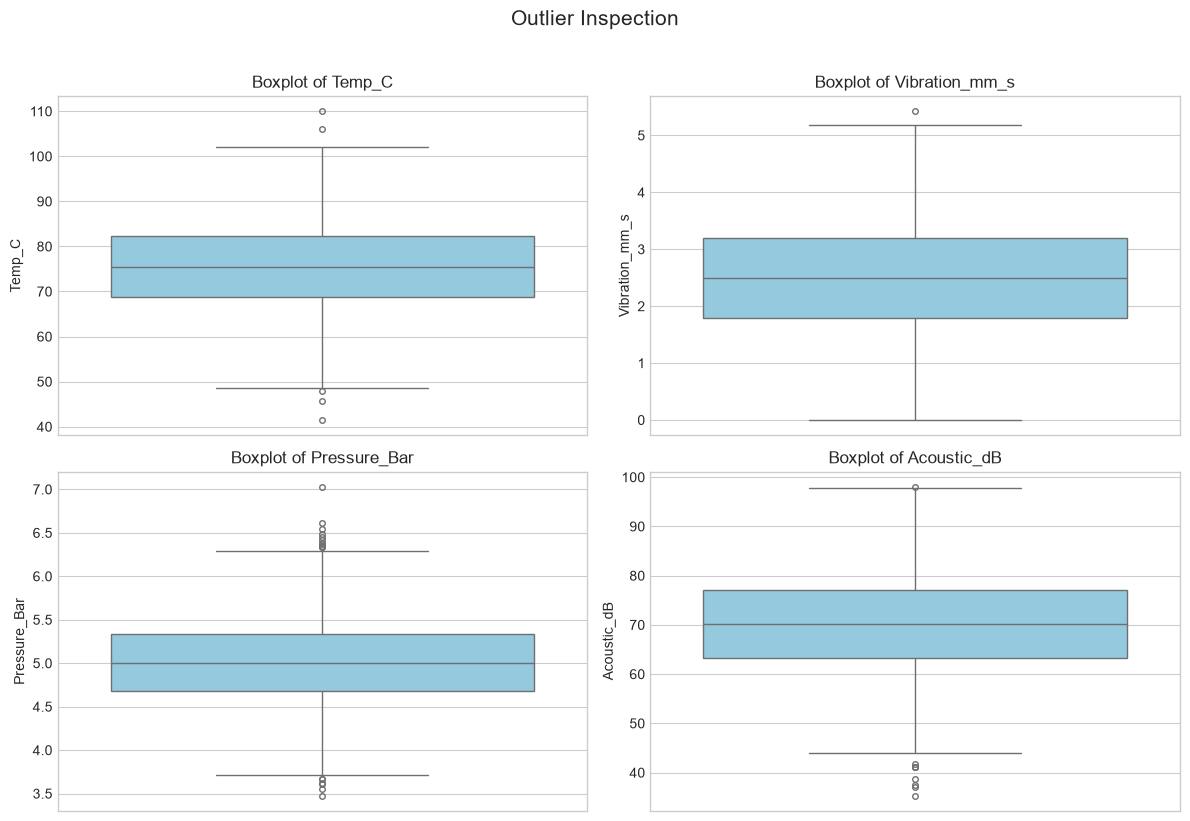

In [10]:
# Select key sensor features for outlier inspection
box_cols = ['Temp_C', 'Vibration_mm_s', 'Pressure_Bar', 'Acoustic_dB']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, col in enumerate(box_cols):
    sns.boxplot(y=df[col], ax=axes[i], color='skyblue', fliersize=4)
    axes[i].set_title(f'Boxplot of {col}', fontsize=12)
    axes[i].set_ylabel(col)

plt.suptitle('Outlier Inspection', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

In [11]:
from scipy.stats import spearmanr

def iqr_outlier_mask(s, k=1.5):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - k * iqr, q3 + k * iqr
    return (s < lo) | (s > hi), lo, hi

outlier_check_cols = ["Pressure_Bar", "Acoustic_dB"]
target = "Failure_Prob"

for col in outlier_check_cols:
    mask, lo, hi = iqr_outlier_mask(df[col])
    n_outliers = mask.sum()

    pearson_full = df[col].corr(df[target])
    pearson_no_outliers = df.loc[~mask, col].corr(df.loc[~mask, target])
    clipped = df[col].clip(lo, hi)
    pearson_clipped = clipped.corr(df[target])
    rho, p_val = spearmanr(df[col], df[target])

    print(f"--- {col} ---")
    print(f"IQR bounds: [{lo:.2f}, {hi:.2f}] | Outliers: {n_outliers} ({n_outliers/len(df)*100:.1f}%)")
    print(f"Pearson corr with {target} -- full: {pearson_full:.3f} | outliers removed: {pearson_no_outliers:.3f} | outliers clipped: {pearson_clipped:.3f}")
    print(f"Spearman corr with {target}: {rho:.3f} (p={p_val:.3g})")
    print()

--- Pressure_Bar ---
IQR bounds: [3.69, 6.33] | Outliers: 17 (1.2%)
Pearson corr with Failure_Prob -- full: -0.019 | outliers removed: -0.027 | outliers clipped: -0.020
Spearman corr with Failure_Prob: -0.024 (p=0.371)

--- Acoustic_dB ---
IQR bounds: [42.58, 97.81] | Outliers: 9 (0.6%)
Pearson corr with Failure_Prob -- full: 0.393 | outliers removed: 0.381 | outliers clipped: 0.392
Spearman corr with Failure_Prob: 0.379 (p=3.53e-50)



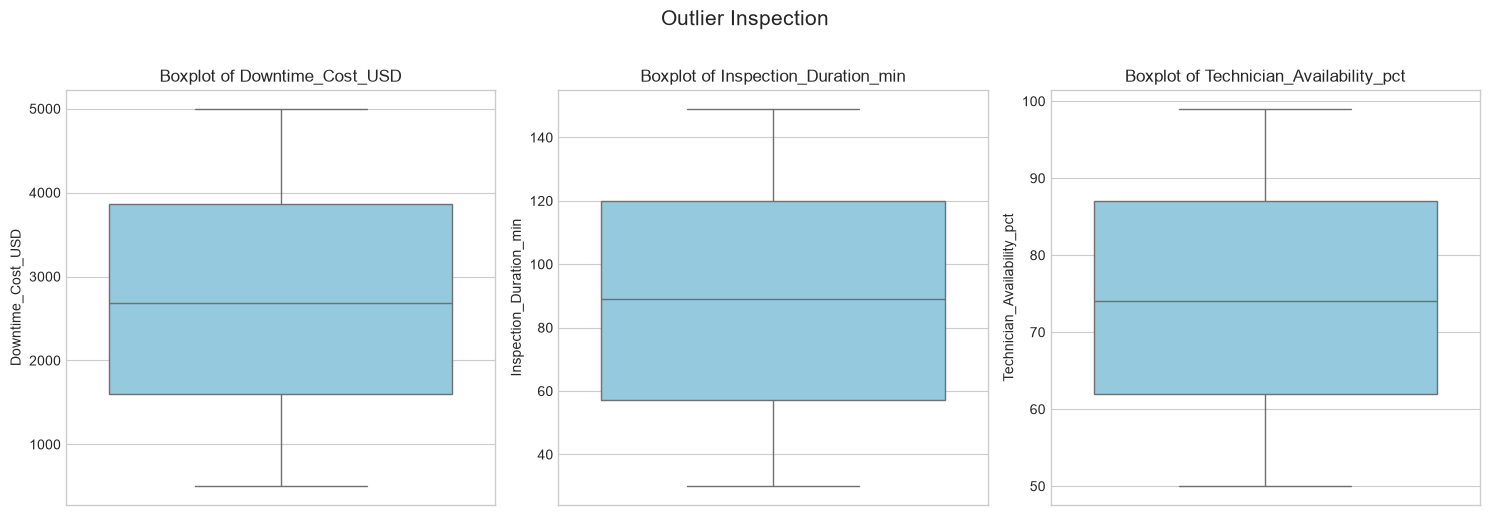

In [12]:
box_cols_2 = ['Downtime_Cost_USD', 'Inspection_Duration_min', 'Technician_Availability_pct']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, col in enumerate(box_cols_2):
    sns.boxplot(y=df[col], ax=axes[i], color='skyblue', fliersize=4)
    axes[i].set_title(f'Boxplot of {col}', fontsize=12)
    axes[i].set_ylabel(col)

plt.suptitle('Outlier Inspection', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

## Bivariate and Correlation Analysis

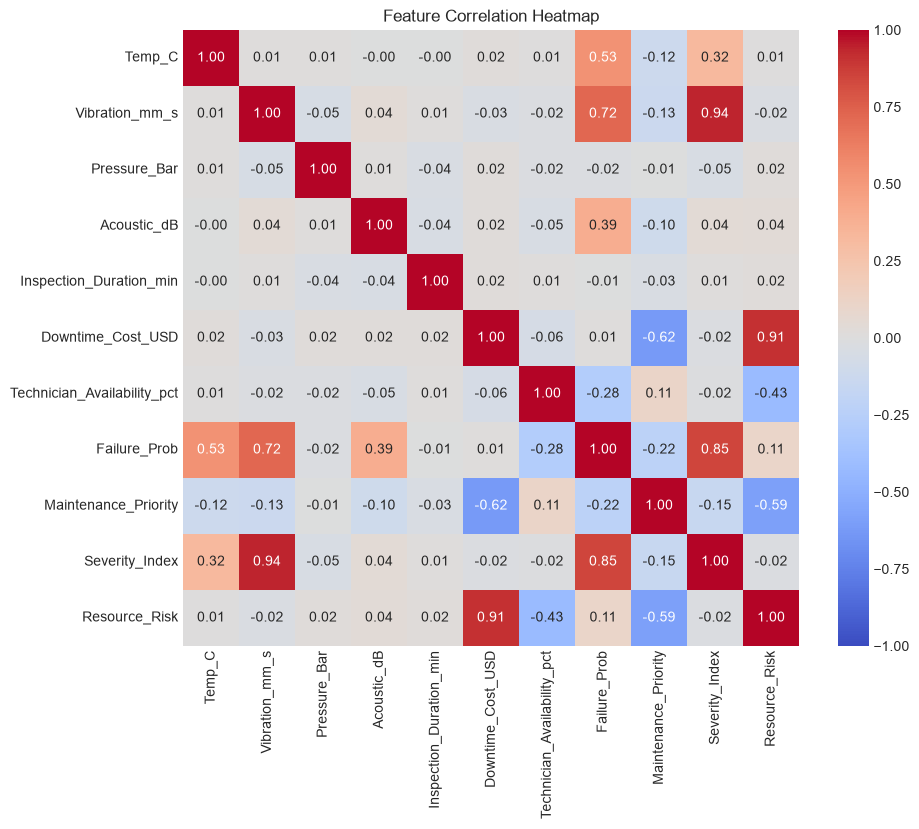

Correlation between Resource_Risk and Downtime_Cost_USD: 0.909


In [13]:
plt.figure(figsize=(10, 8))
numeric_df = df.select_dtypes(include=[np.number]).drop(columns=["Machine_ID"], errors="ignore")
corr_matrix = numeric_df.corr()

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Feature Correlation Heatmap")
plt.show()

high_corr = corr_matrix["Resource_Risk"]["Downtime_Cost_USD"]
print(f"Correlation between Resource_Risk and Downtime_Cost_USD: {high_corr:.3f}")

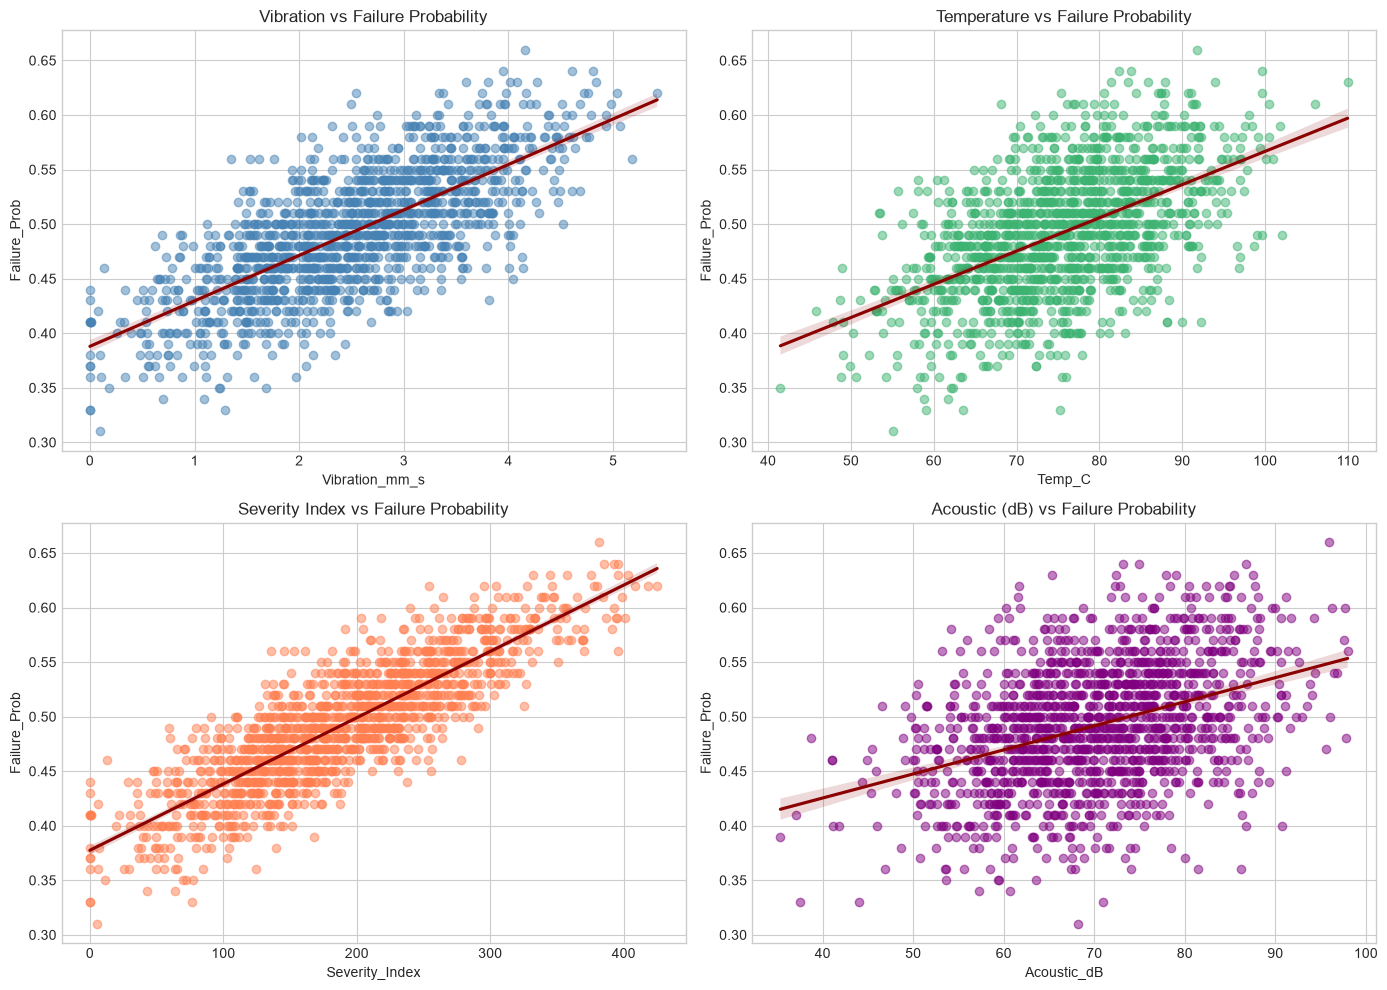

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

# Plot 1: Vibration vs Failure Probability
sns.regplot(
    data=df, 
    x='Vibration_mm_s', 
    y='Failure_Prob', 
    ax=axes[0], 
    scatter_kws={'alpha': 0.5, 'color': 'steelblue'}, 
    line_kws={'color': 'darkred'}
)
axes[0].set_title('Vibration vs Failure Probability')

# Plot 2: Temperature vs Failure Probability
sns.regplot(
    data=df, 
    x='Temp_C', 
    y='Failure_Prob', 
    ax=axes[1], 
    scatter_kws={'alpha': 0.5, 'color': 'mediumseagreen'}, 
    line_kws={'color': 'darkred'}
)
axes[1].set_title('Temperature vs Failure Probability')

# Plot 3: Severity_Index vs Failure Probability
sns.regplot(
    data=df, 
    x='Severity_Index', 
    y='Failure_Prob', 
    ax=axes[2], 
    scatter_kws={'alpha': 0.5, 'color': 'coral'},
    line_kws={'color': 'darkred'}
)
axes[2].set_title('Severity Index vs Failure Probability')

# Plot 4: Acoustic_dB vs Failure Probability
sns.regplot(
    data=df, 
    x='Acoustic_dB', 
    y='Failure_Prob', 
    ax=axes[3], 
    scatter_kws={'alpha': 0.5, 'color': 'purple'},
    line_kws={'color': 'darkred'}
)
axes[3].set_title('Acoustic (dB) vs Failure Probability')

plt.tight_layout()
plt.show()

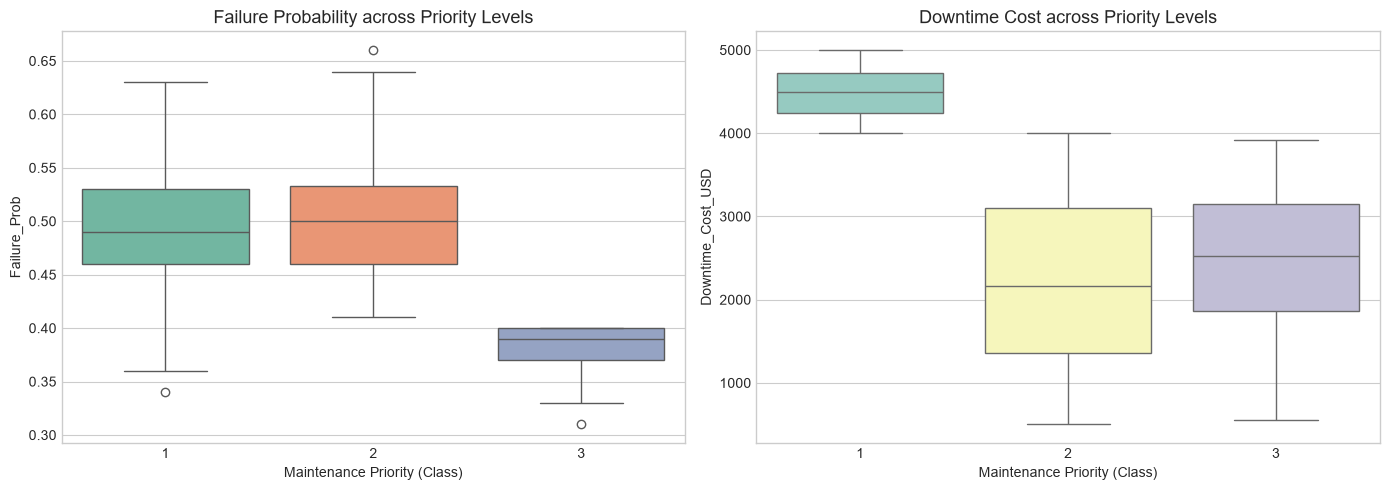

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=df, 
    x='Maintenance_Priority', 
    y='Failure_Prob',
    hue="Maintenance_Priority",
    palette='Set2',
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Failure Probability across Priority Levels', fontsize=13)
axes[0].set_xlabel('Maintenance Priority (Class)')

sns.boxplot(
    data=df, 
    x='Maintenance_Priority', 
    y='Downtime_Cost_USD',
    hue="Maintenance_Priority",
    palette='Set3',
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Downtime Cost across Priority Levels', fontsize=13)
axes[1].set_xlabel('Maintenance Priority (Class)')

plt.tight_layout()
plt.show()

In [16]:
# Group by Machine_ID to calculate aggregated risk and cost metrics
machine_stats = df.groupby('Machine_ID').agg(
    Record_Count=('Machine_ID', 'count'),
    Avg_Failure_Prob=('Failure_Prob', 'mean'),
    Total_Downtime_Cost_USD=('Downtime_Cost_USD', 'sum'),
    Avg_Downtime_Cost_USD=('Downtime_Cost_USD', 'mean'),
    Urgent_Maintenance_Count=('Maintenance_Priority', lambda x: (x == 1).sum())
)

# Sort by Total Downtime Cost to find the most expensive machines
top_expensive_machines = machine_stats.sort_values(by='Total_Downtime_Cost_USD', ascending=False).head(5)

print("--- Top 5 Most Expensive Machines (By Total Downtime Cost) ---")
display(top_expensive_machines.style.background_gradient(subset=['Total_Downtime_Cost_USD', 'Urgent_Maintenance_Count'], cmap='Reds'))

--- Top 5 Most Expensive Machines (By Total Downtime Cost) ---


,Record_Count,Avg_Failure_Prob,Total_Downtime_Cost_USD,Avg_Downtime_Cost_USD,Urgent_Maintenance_Count
Machine_ID,,,,,
M001,167,0.496048,463122,2773.185629,36
M008,144,0.488472,414797,2880.534722,38
M003,154,0.496234,411508,2672.129870,32
M010,149,0.493557,408938,2744.550336,31
M007,142,0.489789,401412,2826.845070,37


## Save Processed Data

In [17]:
df.to_csv(DATA_PROCESSED_PATH, index=False)
print(f"Successfully saved in: {DATA_PROCESSED_PATH}")

Successfully saved in: D:\Projects\smart-manufacturing-maintenance\data\processed\processed_dataset.csv
